## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

print("TensorFlow version:", tf.__version__)

I0000 00:00:1793731824.405212   70725 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793731824.493804   70725 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793731826.963758   70725 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0


## Common text preparation functions

In [2]:
def clean_text(text):
    text = str(text).lower()

    for char in ".,!?;:'\"()[]{}-_/":
        text = text.replace(char, '')

    words = text.split()
    words = [word for word in words if word not in ENGLISH_STOP_WORDS]
    return words


def document_vector(words, word2vec_model):
    vectors = [
        word2vec_model.wv[word]
        for word in words
        if word in word2vec_model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(word2vec_model.vector_size)

    return np.mean(vectors, axis=0)

# 4A. CBOW for Document Classification

**Dataset:** CSV file containing two columns: `review` and `sentiment`.

The sentiment values are `positive` and `negative`. We train CBOW word embeddings from the training reviews, average the word vectors for each review, and use a simple neural network for sentiment classification.


## Stage 1: Load and preprocess the CSV dataset


In [3]:
CSV_PATH = 'dataset/CBOW/imdb.csv'

data = pd.read_csv(CSV_PATH)

print(data.head())
print("Columns:", data.columns.tolist())

data = data.dropna()

reviews = data['review'].astype(str).tolist()
sentiments = data['sentiment'].str.lower().tolist()

# Convert positive/negative labels into 1/0.
labels = [1 if sentiment == 'positive' else 0 for sentiment in sentiments]

review_sentences = [clean_text(review) for review in reviews]

# Remove empty reviews.
valid_rows = [i for i, words in enumerate(review_sentences) if len(words) > 0]
review_sentences = [review_sentences[i] for i in valid_rows]
labels = [labels[i] for i in valid_rows]

train_sentences, test_sentences, y_train, y_test = train_test_split(
    review_sentences,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training reviews:", len(train_sentences))
print("Testing reviews:", len(test_sentences))
print("Example review words:", train_sentences[0][:20])


                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
Columns: ['review', 'sentiment']
Training reviews: 40000
Testing reviews: 10000
Example review words: ['caught', 'little', 'gem', 'totally', 'accident', '1980', '81', 'revival', 'theatre', 'old', 'silly', 'scifi', 'movies', 'theatre', 'packed', 'warning', 'showed', 'bunch', 'scifi', 'short']


## Stage 2: Train Word2Vec using CBOW

Train Word2Vec only on the training reviews. `sg=0` selects the CBOW architecture.


In [4]:
word2vec_model = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=0,
    epochs=10
)

print("Vocabulary size:", len(word2vec_model.wv))

Vocabulary size: 76226


## Stage 3: Convert reviews into vectors and build classifier


In [5]:
X_train = np.array([
    document_vector(words, word2vec_model)
    for words in train_sentences
])

X_test = np.array([
    document_vector(words, word2vec_model)
    for words in test_sentences
])

y_train = np.array(y_train)
y_test = np.array(y_test)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(100,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

E0000 00:00:1793732028.825285   70725 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,529 (25.50 KB)

 Trainable params: 6,529 (25.50 KB)

 Non-trainable params: 0 (0.00 B)

## Stage 4: Train and evaluate the classifier

In [6]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

Epoch 1/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8432 - loss: 0.3655 - val_accuracy: 0.8524 - val_loss: 0.3382
Epoch 2/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8599 - loss: 0.3323 - val_accuracy: 0.8579 - val_loss: 0.3240
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8648 - loss: 0.3246 - val_accuracy: 0.8580 - val_loss: 0.3243
Epoch 4/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8653 - loss: 0.3209 - val_accuracy: 0.8597 - val_loss: 0.3180
Epoch 5/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8646 - loss: 0.3179 - val_accuracy: 0.8625 - val_loss: 0.3176
Epoch 6/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8670 - loss: 0.3144 - val_accuracy: 0.8639 - val_loss: 0.3130
Epoch 7/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8684 - loss: 0.3107 - val_accuracy: 0.8655 - val_loss: 0.3113
Epoch 8/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8711 - loss: 0.3070 - 

### Plot training accuracy and loss

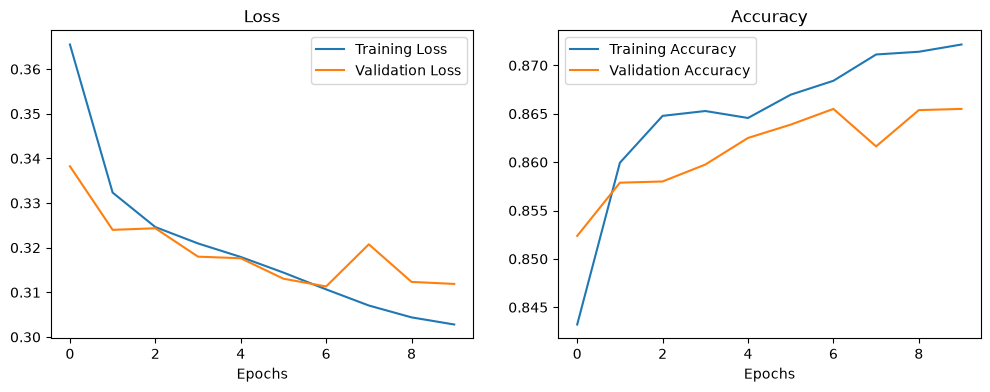

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.legend()

plt.show()

# 4B. CBOW for Twitter Dataset

Download a Twitter dataset from Kaggle and place its CSV file at the path below. This practical trains CBOW word embeddings, finds similar words, and includes a simple tweet recommendation engine.

Set `CSV_PATH` and `TEXT_COLUMN` to match your downloaded file. The recommendation engine compares a user query with the tweets and displays the three most similar tweets.


## Stage 1: Load and preprocess tweets


In [8]:
CSV_PATH = 'dataset/CBOW/twitter_dataset.csv'
TEXT_COLUMN = 'Text'

data = pd.read_csv(CSV_PATH)

print(data.head())
print("Columns:", data.columns.tolist())

tweets = data[TEXT_COLUMN].dropna().astype(str).tolist()
tweet_sentences = [clean_text(tweet) for tweet in tweets]
tweet_sentences = [words for words in tweet_sentences if len(words) > 0]

print("Number of tweets:", len(tweet_sentences))
print("Example tokens:", tweet_sentences[0][:20])


   Tweet_ID        Username  \
0         1         julie81   
1         2   richardhester   
2         3  williamsjoseph   
3         4     danielsmary   
4         5      carlwarren   

                                                Text  Retweets  Likes  \
0  Party least receive say or single. Prevent pre...         2     25   
1  Hotel still Congress may member staff. Media d...        35     29   
2  Nice be her debate industry that year. Film wh...        51     25   
3  Laugh explain situation career occur serious. ...        37     18   
4  Involve sense former often approach government...        27     80   

             Timestamp  
0  2023-01-30 11:00:51  
1  2023-01-02 22:45:58  
2  2023-01-18 11:25:19  
3  2023-04-10 22:06:29  
4  2023-01-24 07:12:21  
Columns: ['Tweet_ID', 'Username', 'Text', 'Retweets', 'Likes', 'Timestamp']
Number of tweets: 10000
Example tokens: ['party', 'receive', 'say', 'single', 'prevent', 'prevent', 'husband', 'affect', 'cup', 'style', 'evening', 

## Stage 2: Train Word2Vec using CBOW

In [9]:
twitter_model = Word2Vec(
    sentences=tweet_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=0,
    epochs=10
)

print("Vocabulary size:", len(twitter_model.wv))

Vocabulary size: 763


## Stage 3: Check learned word embeddings


In [10]:
word = twitter_model.wv.index_to_key[0]

print("Example word:", word)
print("Word vector:", twitter_model.wv[word])

print("Similar words:")
print(twitter_model.wv.most_similar(word, topn=5))

Example word: hard
Word vector: [-0.02279432  0.14532931  0.11786876  0.0797022  -0.04760994 -0.25067234
 -0.0947973   0.258824   -0.01224492  0.01056689 -0.15127285 -0.13970293
 -0.0377684  -0.00823825  0.00428221 -0.04883889  0.01009391 -0.0572687
  0.02481894 -0.15643635  0.08783844  0.11539327 -0.0013141   0.00684694
 -0.03941601 -0.00933791 -0.2236804  -0.1116358   0.0147693   0.1202625
  0.18617924  0.15469316  0.00977049  0.12522341 -0.12706237  0.16651376
 -0.09114853 -0.27363452 -0.09028346 -0.28257656 -0.08209405  0.03931694
  0.00392305 -0.05042463  0.0352012  -0.14148076 -0.10393286  0.08011441
 -0.01543865 -0.01225073 -0.03318831 -0.17610589 -0.14795695 -0.02198844
 -0.17676781  0.08905888  0.17229949 -0.08753815 -0.15436898  0.04497393
  0.05107703  0.11227208 -0.29354087 -0.06002764 -0.25901648 -0.02861531
  0.06082105  0.03492611 -0.11947377 -0.04921106 -0.06996151 -0.03259511
  0.1399964  -0.10646685  0.02431227  0.04877239 -0.01923233 -0.17474715
 -0.1128009   0.06347

## Stage 4: Simple Tweet Recommendation Engine

Convert each tweet into an average word vector. Then compare a user query with all tweet vectors using cosine similarity.

In [11]:
# Create one vector for each tweet.
tweet_vectors = np.array([
    document_vector(words, twitter_model)
    for words in tweet_sentences
])

user_input = "machine learning and artificial intelligence"

user_words = clean_text(user_input)
user_vector = document_vector(user_words, twitter_model)

similarities = cosine_similarity(
    user_vector.reshape(1, -1),
    tweet_vectors
)[0]

top_indices = np.argsort(similarities)[::-1][:3]

print("Recommended tweets:")
for index in top_indices:
    print("\nSimilarity:", round(similarities[index], 3))
    print(" ".join(tweet_sentences[index]))


Recommended tweets:

Similarity: 0.986
difficult citizen environment western energy loss machine memory low fall drive dinner color car board natural opportunity machine ok little

Similarity: 0.986
choice machine director bag citizen position sing result base bring chair dog likely technology employee identify way tv fall plan pull laugh late offer research develop material budget land

Similarity: 0.985
government recently later situation machine kind family actually nearly forget production point degree present better rate bank loss remain traditional chance office spend election action light author kitchen hot perform


# 4C. CBOW for a Given Textual Document

This practical loads the text from `document3.txt`, trains Word2Vec using CBOW, and displays example word vectors and similar words.

Place `document3.txt` in the same folder as this notebook, or update `DOCUMENT_PATH` below.


## Stage 1: Load and prepare document3


In [12]:
DOCUMENT_PATH = 'dataset/CBOW/document3.txt'

with open(DOCUMENT_PATH, 'r') as file:
    document3 = file.read()

sentences = [clean_text(document3)]
sentences = [words for words in sentences if len(words) > 0]

print("Number of words:", len(sentences[0]))
print("Tokens:", sentences[0])

Number of words: 101
Tokens: ['speed', 'transmission', 'important', 'point', 'difference', 'viruses', 'influenza', 'shorter', 'median', 'incubation', 'period', 'time', 'infection', 'appearance', 'symptoms', 'shorter', 'serial', 'interval', 'time', 'successive', 'cases', 'covid19', 'virus', 'serial', 'interval', 'covid19', 'virus', 'estimated', '56', 'days', 'influenza', 'virus', 'serial', 'interval', '3', 'days', 'means', 'influenza', 'spread', 'faster', 'covid19', 'transmission', '35', 'days', 'illness', 'potentially', 'presymptomatic', 'transmission', '–transmission', 'virus', 'appearance', 'symptoms', '–', 'major', 'driver', 'transmission', 'influenza', 'contrast', 'learning', 'people', 'shed', 'covid19', 'virus', '2448', 'hours', 'prior', 'symptom', 'onset', 'present', 'does', 'appear', 'major', 'driver', 'transmission', 'reproductive', 'number', '–', 'number', 'secondary', 'infections', 'generated', 'infected', 'individual', '–', 'understood', '2', '25', 'covid19', 'virus', 'highe

## Stage 2: Train Word2Vec using CBOW

In [13]:
document_model = Word2Vec(
    sentences=sentences,
    vector_size=50,
    window=2,
    min_count=1,
    workers=1,
    sg=0,
    epochs=100
)

print("Vocabulary:", document_model.wv.index_to_key)

Vocabulary: ['virus', 'covid19', 'influenza', 'transmission', '–', 'days', 'interval', 'serial', 'number', 'driver', 'major', 'symptoms', 'appearance', 'time', 'shorter', 'viruses', 'difficult', 'comparisons', 'direct', 'making', 'timespecific', 'context', 'estimates', 'higher', '25', '2', 'understood', 'individual', 'infected', 'generated', 'infections', 'secondary', 'reproductive', 'appear', 'does', 'present', 'onset', 'symptom', 'prior', 'hours', '2448', 'shed', 'people', 'learning', 'contrast', '–transmission', 'presymptomatic', 'potentially', 'illness', '35', 'faster', 'spread', 'means', '3', '56', 'estimated', 'cases', 'successive', 'infection', 'period', 'incubation', 'median', 'difference', 'point', 'important', 'speed']


## Stage 3: Evaluate the learned word embeddings

In [14]:
word = document_model.wv.index_to_key[0]

print("Selected word:", word)
print("Word vector:", document_model.wv[word])

if len(document_model.wv) > 1:
    print("Similar words:")
    print(document_model.wv.most_similar(word, topn=min(5, len(document_model.wv) - 1)))

Selected word: virus
Word vector: [ 0.00521779 -0.00148789  0.01185733  0.02732649 -0.02437597 -0.02176943
  0.0277727   0.03290512 -0.02251025 -0.01481173  0.01618861 -0.02277026
  0.00885358  0.02426413 -0.00990188  0.0060514   0.02579392  0.00400685
 -0.03151276 -0.03911329  0.0212946   0.01664363  0.02867919 -0.00284293
  0.01759133 -0.0041041  -0.01309317  0.03089092 -0.01715704 -0.00341073
 -0.01603591 -0.00938909  0.02039129 -0.02543158 -0.01151168 -0.00652594
  0.03348845 -0.01092425  0.00279599 -0.00302521 -0.00531361  0.00117216
 -0.01783464 -0.0084849   0.0176052  -0.01195444 -0.01964514  0.00963231
  0.01670296  0.03126605]
Similar words:
[('influenza', 0.6691297888755798), ('shorter', 0.6549602150917053), ('covid19', 0.6171254515647888), ('higher', 0.5733487010002136), ('serial', 0.569790780544281)]
